# RAPID peak-dot comparison animation

This notebook compares a base network with one collapsed-network variant. All timing is measured from each run's own event start (the same forcing timestamp), then mapped onto one shared elapsed-time clock. A dot reaches a parent-link midpoint at that link's discharge peak.

This is deliberately a *peak-time* animation, not a wave-intensity animation. It does not show water moving along a single reach: it shows the downstream sequence of link peaks. For a flat peak, use the midpoint of the maximum plateau to avoid choosing an arbitrary first maximum.

The overlay chapter has four motion modes: `midpoint_timing` (the original connected trajectory), `hybrid_midpoint_timing` (the original timing with continuous speed at shared midpoints), `observed_link_speed` (per-link timing measured between its first and last RAPID subreach peaks), and `celerity` (per-link travel duration from RAPID `K`). It also has `dot`, `peak_plus_width`, and `hydro_pulse` appearances. The latter two use the duration above 50% of local peak excess as a visible local wave width.

In [1]:
network = 56
TARGET_STATE = 'CB003_bubble_5'  # change to any state in rapid_run_registry.csv


In [2]:
from pathlib import Path
import sys

REPO = Path.cwd().resolve().parents[1]  # run this notebook from RAPID/notebooks
if not (REPO / 'RAPID' / 'src').exists():
    REPO = Path('/Users/6256481/Code/river-hierarchy')
sys.path.insert(0, str(REPO / 'RAPID' / 'src'))

EXPERIMENT = REPO / f'network_variants/output/{network}_compound_bubbles__anchored'
REFERENCE_STATE = 'S000_base'
OUTPUT_GIF = EXPERIMENT / f'{TARGET_STATE}_vs_{REFERENCE_STATE}_peak_dots.gif'

# Peak definition. Midpoint is recommended when peaks occupy several time steps.
PEAK_RULE = 'midpoint_of_plateau'  # 'first_max' or 'midpoint_of_plateau'
PEAK_RELATIVE_TOLERANCE = 1e-6
WAVE_WIDTH_RELATIVE_LEVEL = 0.80  # shoulder dots: rising/receding fraction of local peak excess; use 0.50 for broader pulses
OBSERVED_SPEED_REGULARIZATION = 0.03  # weak anchor to RAPID K when peak equations are underdetermined

# Motion: 'midpoint_timing' (original), 'hybrid_midpoint_timing',
# 'observed_link_speed', 'network_observed_link_speed', or 'celerity'. The hybrid keeps exact peak times
# but smooths speed changes at shared link midpoints.
MOTION_MODE = 'hybrid_midpoint_timing'
N_FRAMES = 360
FRAME_DURATION_MS = 95  # about 34 seconds total, with visibly smooth motion
# Hybrid needs finer simulation-time sampling: short RAPID links can traverse
# in less than one regular GIF frame. Keep the viewing duration near 36 s.
HYBRID_N_FRAMES = 720
HYBRID_FRAME_DURATION_MS = 20
DOT_SIZE = 38


In [3]:
import numpy as np
import pandas as pd
from rapid_tools.analysis import _load_wave_state

registry = pd.read_csv(EXPERIMENT / 'rapid_run_registry.csv')
available_states = registry.loc[registry.status.eq('ran'), 'state_id'].tolist()
print(f'{len(available_states)} runnable states: {available_states}')
assert REFERENCE_STATE in available_states
assert TARGET_STATE in available_states

reference = _load_wave_state(EXPERIMENT, REFERENCE_STATE)
target = _load_wave_state(EXPERIMENT, TARGET_STATE)
def common_elapsed_time(reference, target):
    """Align RAPID outputs by elapsed time since their own event starts."""
    reference_time = reference.wave_stack.time_seconds - float(reference.run_row['event_start_time_seconds'])
    target_time = target.wave_stack.time_seconds - float(target.run_row['event_start_time_seconds'])
    time, reference_index, target_index = np.intersect1d(
        reference_time, target_time, return_indices=True
    )
    # Do not animate pre-event values, and retain only the shared simulation extent.
    keep = time >= 0
    time = time[keep]
    reference_index, target_index = reference_index[keep], target_index[keep]
    if time.size == 0:
        raise ValueError('The two runs have no common post-event RAPID timesteps.')
    return time, reference.wave_stack.qout[reference_index], target.wave_stack.qout[target_index]

time_seconds, reference_qout, target_qout = common_elapsed_time(reference, target)
print(f'Common post-event window: {len(time_seconds)} steps, {time_seconds[-1] / 3600:.1f} hours')
print('Both event starts have UTC timestamp:', reference.run_row.event_start_time_utc, target.run_row.event_start_time_utc)


6 runnable states: ['S000_base', 'CB001_bubble_8', 'CB002_bubble_4', 'CB003_bubble_5', 'CB004_bubble_6', 'CB005_bubble_9']
Common post-event window: 3185 steps, 955.2 hours
Both event starts have UTC timestamp: 2025-06-26T20:24:00+00:00 2025-06-26T20:24:00+00:00


In [4]:
def parent_peak_frame(reaches, qout, time_seconds, *, peak_rule, relative_tolerance):
    """Aggregate RAPID subreaches by parent link and calculate one robust peak time."""
    frame = reaches[['parent_link_id', 'id_us_node', 'id_ds_node', 'subreach_index', 'rapid_k', 'geometry']].copy()
    frame['parent_link_id'] = pd.to_numeric(frame['parent_link_id'], errors='coerce')
    frame = frame.loc[frame.parent_link_id.notna()].copy()
    frame['parent_link_id'] = frame.parent_link_id.astype(int)
    # RAPID splits each parent link into subreaches. Preserve the parent endpoints:
    # first subreach upstream node and *last* subreach downstream node.
    endpoint_metadata = (
        frame.sort_values(['parent_link_id', 'subreach_index'])
        .groupby('parent_link_id', as_index=False)
        .agg(id_us_node=('id_us_node', 'first'), id_ds_node=('id_ds_node', 'last'))
    )
    parent_geometry = frame[['parent_link_id', 'geometry']].dissolve(by='parent_link_id', as_index=False)
    # RAPID stores each parent link as several subreaches.  Merge contiguous
    # pieces so line styles (especially dashes) run along the whole link.
    from shapely.ops import linemerge
    parent_geometry['geometry'] = parent_geometry.geometry.map(
        lambda geometry: linemerge(geometry) if geometry.geom_type == 'MultiLineString' else geometry
    )
    parent_geometry = parent_geometry.merge(endpoint_metadata, on='parent_link_id', validate='one_to_one')
    parent_ids = frame.parent_link_id.to_numpy()
    rows = []
    timestep_seconds = float(np.median(np.diff(time_seconds)))

    def peak_index(series):
        peak = np.nanmax(series)
        if peak_rule == 'first_max':
            return int(np.nanargmax(series))
        if peak_rule == 'midpoint_of_plateau':
            indices = np.flatnonzero(np.isclose(series, peak, rtol=relative_tolerance, atol=0.0))
            return int(np.rint(np.mean(indices)))
        raise ValueError(f'Unknown peak rule: {peak_rule}')

    for parent_link_id in parent_geometry.parent_link_id:
        parent = frame.loc[frame.parent_link_id.eq(parent_link_id)].sort_values('subreach_index')
        parent_mask = parent_ids == parent_link_id
        series = np.nanmean(qout[:, parent_mask], axis=1)
        peak_at = peak_index(series)
        # Width of the local hydrograph, measured at a configurable fraction of
        # its excess above the pre-event/local minimum. This controls pulse length.
        baseline, peak = np.nanmin(series), np.nanmax(series)
        threshold = baseline + WAVE_WIDTH_RELATIVE_LEVEL * (peak - baseline)
        above_threshold = series >= threshold
        # Use only the connected threshold interval containing this selected
        # peak, rather than unrelated high-flow periods elsewhere in the run.
        left = right = peak_at
        while left > 0 and above_threshold[left - 1]:
            left -= 1
        while right < len(series) - 1 and above_threshold[right + 1]:
            right += 1
        wave_width = time_seconds[right] - time_seconds[left]
        # Observed within-link travel time uses first and last RAPID subreaches.
        # A one-subreach parent has no internal observation, so falls back to K.
        configured_seconds = float(pd.to_numeric(parent.rapid_k, errors='coerce').sum())
        observed_seconds = configured_seconds
        if len(parent) > 1:
            upstream = np.nanmean(qout[:, parent_mask & frame.subreach_index.eq(parent.subreach_index.iloc[0]).to_numpy()], axis=1)
            downstream = np.nanmean(qout[:, parent_mask & frame.subreach_index.eq(parent.subreach_index.iloc[-1]).to_numpy()], axis=1)
            observed_seconds = time_seconds[peak_index(downstream)] - time_seconds[peak_index(upstream)]
        observed_seconds = float(observed_seconds) if np.isfinite(observed_seconds) and observed_seconds > 0 else configured_seconds
        rows.append({'parent_link_id': parent_link_id, 'peak_time_seconds': time_seconds[peak_at],
                     'peak_width_seconds': max(float(wave_width), timestep_seconds),
                     'observed_link_travel_seconds': max(float(observed_seconds), timestep_seconds),
                     'celerity_link_travel_seconds': max(configured_seconds, timestep_seconds)})
    peaks = pd.DataFrame(rows)
    result = parent_geometry.merge(peaks, on='parent_link_id', validate='one_to_one')
    points = result.geometry.interpolate(0.5, normalized=True)
    result['x'] = points.x
    result['y'] = points.y
    return result

base_peaks = parent_peak_frame(reference.wave_stack.reaches, reference_qout, time_seconds, peak_rule=PEAK_RULE, relative_tolerance=PEAK_RELATIVE_TOLERANCE)
variant_peaks = parent_peak_frame(target.wave_stack.reaches, target_qout, time_seconds, peak_rule=PEAK_RULE, relative_tolerance=PEAK_RELATIVE_TOLERANCE)
matched = base_peaks[['parent_link_id', 'peak_time_seconds']].merge(
    variant_peaks[['parent_link_id', 'peak_time_seconds']], on='parent_link_id', suffixes=('_base', '_variant')
)
matched['delta_peak_hours'] = (matched.peak_time_seconds_variant - matched.peak_time_seconds_base) / 3600
display(matched.delta_peak_hours.describe())

def subreach_wave_field(reaches, qout):
    """Local RAPID hydrographs for a spatial, non-icon wave rendering."""
    paths = []
    columns = []
    for column, geometry in enumerate(reaches.geometry):
        parts = geometry.geoms if geometry.geom_type == 'MultiLineString' else [geometry]
        for part in parts:
            paths.append(np.asarray(part.coords))
            columns.append(column)
    baseline = np.nanmin(qout, axis=0)
    scale = np.maximum(np.nanmax(qout, axis=0) - baseline, np.finfo(float).eps)
    return {'paths': paths, 'columns': np.asarray(columns), 'qout': qout, 'baseline': baseline, 'scale': scale}

base_wave_field = subreach_wave_field(reference.wave_stack.reaches, reference_qout)
variant_wave_field = subreach_wave_field(target.wave_stack.reaches, target_qout)


count    41.000000
mean     -9.065854
std       7.343726
min     -15.000000
25%     -15.000000
50%     -14.700000
75%       0.000000
max       0.000000
Name: delta_peak_hours, dtype: float64

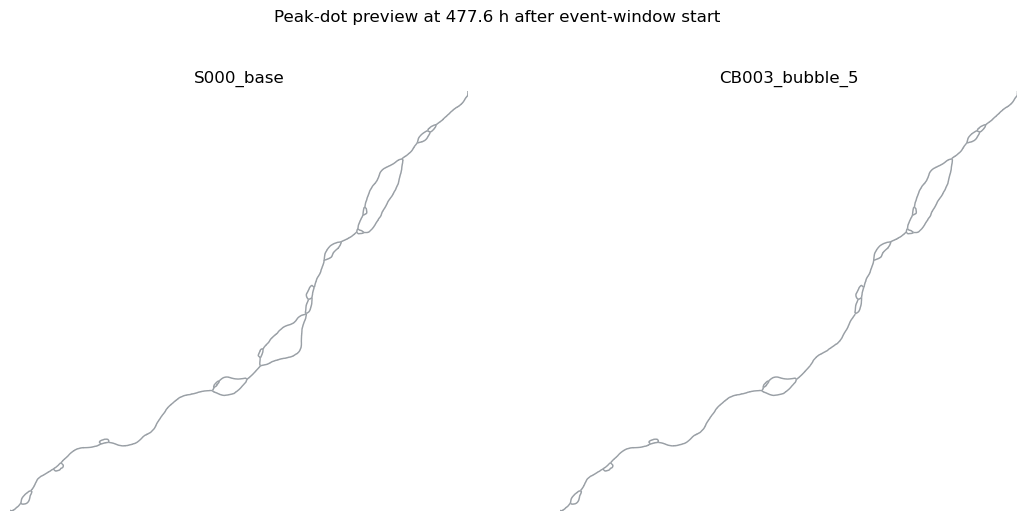

In [5]:
import matplotlib.pyplot as plt

def draw_network(ax, links, active, *, title, bounds):
    links.plot(ax=ax, color='#9aa0a6', linewidth=1.0, zorder=1)
    ax.scatter(active.x, active.y, s=DOT_SIZE, c='#d62728', edgecolors='white', linewidths=0.45, zorder=2)
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]), title=title)
    ax.set_aspect('equal')
    ax.set_axis_off()

all_bounds = np.array([
    min(base_peaks.total_bounds[0], variant_peaks.total_bounds[0]),
    min(base_peaks.total_bounds[1], variant_peaks.total_bounds[1]),
    max(base_peaks.total_bounds[2], variant_peaks.total_bounds[2]),
    max(base_peaks.total_bounds[3], variant_peaks.total_bounds[3]),
])
preview_time = np.median(time_seconds)
time_step = np.median(np.diff(time_seconds))
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
draw_network(axes[0], base_peaks, base_peaks[np.abs(base_peaks.peak_time_seconds - preview_time) <= time_step / 2], title=REFERENCE_STATE, bounds=all_bounds)
draw_network(axes[1], variant_peaks, variant_peaks[np.abs(variant_peaks.peak_time_seconds - preview_time) <= time_step / 2], title=TARGET_STATE, bounds=all_bounds)
fig.suptitle(f'Peak-dot preview at {(preview_time - time_seconds[0]) / 3600:.1f} h after event-window start')
plt.show()


In [6]:
from shapely.geometry import LineString
from shapely.ops import linemerge, substring

def as_single_line(geometry):
    """Return a continuous line where possible; retain the longest part otherwise."""
    merged = linemerge(geometry) if geometry.geom_type == 'MultiLineString' else geometry
    if merged.geom_type == 'LineString':
        return merged
    return max(merged.geoms, key=lambda part: part.length)

def half_path(line, *, from_midpoint, endpoint):
    """Extract a curved half-link path, preserving all centreline vertices."""
    midpoint_distance = 0.5 * line.length
    endpoint_distance = float(endpoint) * line.length
    if from_midpoint:
        return substring(line, midpoint_distance, endpoint_distance)
    return substring(line, endpoint_distance, midpoint_distance)

def path_between_midpoints(source_geometry, target_geometry):
    """Join two link midpoints through their nearest endpoints.

    The graph topology selects valid downstream links; nearest endpoints only chooses
    the drawing direction along the stored centreline coordinates.
    """
    source, target = as_single_line(source_geometry), as_single_line(target_geometry)
    source_ends = [source.interpolate(0, normalized=True), source.interpolate(1, normalized=True)]
    target_ends = [target.interpolate(0, normalized=True), target.interpolate(1, normalized=True)]
    source_end, target_end = min(
        ((i, j) for i in range(2) for j in range(2)),
        key=lambda pair: source_ends[pair[0]].distance(target_ends[pair[1]]),
    )
    first = half_path(source, from_midpoint=True, endpoint=source_end)
    second = half_path(target, from_midpoint=False, endpoint=target_end)
    return LineString(list(first.coords) + list(second.coords)[1:])

def midpoint_timing_segments(peaks):
    """One mover reaches each downstream midpoint exactly at its peak time."""
    rows, downstream_nodes = [], set(peaks.id_ds_node.dropna().astype(int))
    for source in peaks.itertuples(index=False):
        downstream = peaks.loc[peaks.id_us_node.eq(source.id_ds_node)]
        for target_row in downstream.itertuples(index=False):
            if target_row.peak_time_seconds <= source.peak_time_seconds:
                continue  # no backwards/instantaneous visual path
            rows.append({
                'start_seconds': source.peak_time_seconds,
                'end_seconds': target_row.peak_time_seconds,
                'geometry': path_between_midpoints(source.geometry, target_row.geometry),
                'start_peak_width_seconds': source.peak_width_seconds,
                'peak_width_seconds': target_row.peak_width_seconds,
                'start_link_id': source.parent_link_id,
                'end_link_id': target_row.parent_link_id,
            })
    # Inlets enter from their upstream endpoint at event time zero, then reach their midpoint at its peak.
    for inlet in peaks.loc[~peaks.id_us_node.isin(downstream_nodes)].itertuples(index=False):
        if inlet.peak_time_seconds <= 0:
            continue
        line = as_single_line(inlet.geometry)
        rows.append({
            'start_seconds': 0.0,
            'end_seconds': inlet.peak_time_seconds,
            'geometry': half_path(line, from_midpoint=False, endpoint=0),
            'start_peak_width_seconds': inlet.peak_width_seconds,
            'peak_width_seconds': inlet.peak_width_seconds,
            'start_link_id': np.nan,
            'end_link_id': inlet.parent_link_id,
        })
    return pd.DataFrame(rows)

def hybrid_midpoint_segments(peaks):
    """Keep peak-time waypoints, while matching speed across shared midpoints."""
    movers = midpoint_timing_segments(peaks).copy()
    movers['geometry_length'] = movers.geometry.map(lambda geometry: geometry.length)
    movers['mean_speed'] = movers.geometry_length / (movers.end_seconds - movers.start_seconds)
    # Each link midpoint is a waypoint. Its harmonic-mean incident speed avoids
    # a sudden speed jump while preserving the exact waypoint time and location.
    waypoint_speeds = {}
    for link_id in peaks.parent_link_id:
        incident = pd.concat([
            movers.loc[movers.end_link_id.eq(link_id), 'mean_speed'],
            movers.loc[movers.start_link_id.eq(link_id), 'mean_speed'],
        ]).to_numpy(dtype=float)
        incident = incident[np.isfinite(incident) & (incident > 0)]
        if incident.size:
            waypoint_speeds[link_id] = incident.size / np.sum(1.0 / incident)
    movers['start_speed'] = [waypoint_speeds.get(link_id, speed) for link_id, speed in zip(movers.start_link_id, movers.mean_speed)]
    movers['end_speed'] = [waypoint_speeds.get(link_id, speed) for link_id, speed in zip(movers.end_link_id, movers.mean_speed)]
    duration = movers.end_seconds - movers.start_seconds
    # Slopes are d(distance fraction)/d(time fraction). Clipping keeps the
    # cubic interpolation monotonic even for strongly different link speeds.
    movers['start_slope'] = np.clip(movers.start_speed * duration / movers.geometry_length, 0.05, 2.5)
    movers['end_slope'] = np.clip(movers.end_speed * duration / movers.geometry_length, 0.05, 2.5)
    movers['motion_profile'] = 'hybrid'
    return movers

def infer_network_observed_link_times(peaks, regularization=OBSERVED_SPEED_REGULARIZATION):
    """Infer one effective peak travel time per link from all adjacent peak pairs."""
    link_ids = peaks.parent_link_id.to_numpy()
    index = {link_id: i for i, link_id in enumerate(link_ids)}
    equations, observations = [], []
    for source in peaks.itertuples(index=False):
        for target in peaks.loc[peaks.id_us_node.eq(source.id_ds_node)].itertuples(index=False):
            delay = target.peak_time_seconds - source.peak_time_seconds
            if delay <= 0:
                continue
            row = np.zeros(len(peaks))
            row[index[source.parent_link_id]] = 1.0
            row[index[target.parent_link_id]] = 1.0
            equations.append(row)
            observations.append(2.0 * delay)
    if not equations:
        raise ValueError('No positive adjacent peak-time delays available for observed-speed inference.')
    # Peak equations can be underdetermined on an alternating branch graph.
    # A weak K-based anchor selects a stable, positive effective link time.
    anchor = peaks.celerity_link_travel_seconds.to_numpy(dtype=float)
    design = np.vstack([np.vstack(equations), np.sqrt(regularization) * np.eye(len(peaks))])
    rhs = np.concatenate([np.asarray(observations), np.sqrt(regularization) * anchor])
    inferred = np.linalg.lstsq(design, rhs, rcond=None)[0]
    timestep = float(np.median(np.diff(time_seconds)))
    result = peaks.copy()
    result['network_observed_link_travel_seconds'] = np.maximum(inferred, timestep)
    return result

def individual_link_segments(peaks, travel_time_column):
    """Move independently along every full parent link, centred on its peak."""
    rows = []
    for link in peaks.itertuples(index=False):
        travel_seconds = max(float(getattr(link, travel_time_column)), 1.0)
        rows.append({'start_seconds': link.peak_time_seconds - travel_seconds / 2,
                     'end_seconds': link.peak_time_seconds + travel_seconds / 2,
                     'geometry': as_single_line(link.geometry),
                     'start_peak_width_seconds': link.peak_width_seconds,
                     'peak_width_seconds': link.peak_width_seconds})
    return pd.DataFrame(rows)

def build_movers(peaks, motion_mode):
    if motion_mode == 'midpoint_timing':
        return midpoint_timing_segments(peaks)
    if motion_mode == 'hybrid_midpoint_timing':
        return hybrid_midpoint_segments(peaks)
    if motion_mode == 'observed_link_speed':
        return individual_link_segments(peaks, 'observed_link_travel_seconds')
    if motion_mode == 'network_observed_link_speed':
        inferred = infer_network_observed_link_times(peaks)
        return individual_link_segments(inferred, 'network_observed_link_travel_seconds')
    if motion_mode == 'celerity':
        return individual_link_segments(peaks, 'celerity_link_travel_seconds')
    raise ValueError("MOTION_MODE must be 'midpoint_timing', 'hybrid_midpoint_timing', 'observed_link_speed', 'network_observed_link_speed', or 'celerity'.")

base_movers = build_movers(base_peaks, MOTION_MODE)
variant_movers = build_movers(variant_peaks, MOTION_MODE)
print(f'{MOTION_MODE}: base={len(base_movers)} movers, variant={len(variant_movers)} movers')


hybrid_midpoint_timing: base=61 movers, variant=55 movers


## Additional wave styles

The pulse-dot and reference-peak-wave modes are configured in the existing overlay cell below.

Use `hydro_pulse_dots` for three-dot pulses (peak plus shoulders) and `reference_peak_wave` for blue base geometry with a red travelling reference peak.

In [7]:
# Configure and render the additional styles in the overlay cell below.


## Base vs variant animation

This view puts the variant next to the base network. 



In [8]:
import matplotlib.pyplot as plt
from PIL import Image
from tempfile import TemporaryDirectory

all_bounds = np.array([
    min(base_peaks.total_bounds[0], variant_peaks.total_bounds[0]),
    min(base_peaks.total_bounds[1], variant_peaks.total_bounds[1]),
    max(base_peaks.total_bounds[2], variant_peaks.total_bounds[2]),
    max(base_peaks.total_bounds[3], variant_peaks.total_bounds[3]),
])
animation_end_seconds = max(base_movers.end_seconds.max(), variant_movers.end_seconds.max())
frame_times = np.linspace(0.0, animation_end_seconds, N_FRAMES)

def mover_fraction(mover, current_time):
    linear_fraction = (current_time - mover.start_seconds) / (mover.end_seconds - mover.start_seconds)
    if getattr(mover, 'motion_profile', None) != 'hybrid':
        return float(linear_fraction)
    # Cubic Hermite timing: exact endpoints/peak times, continuous speed at
    # their shared waypoint, and no positional overshoot.
    u = float(linear_fraction)
    return float((u**3 - 2*u**2 + u) * mover.start_slope + (-2*u**3 + 3*u**2) + (u**3 - u**2) * mover.end_slope)

def mover_points(movers, current_time):
    active = movers.loc[movers.start_seconds.le(current_time) & movers.end_seconds.ge(current_time)]
    points = []
    for mover in active.itertuples(index=False):
        points.append(mover.geometry.interpolate(mover_fraction(mover, current_time), normalized=True))
    return points

def draw_movers(ax, links, movers, current_time, *, title):
    links.plot(ax=ax, color='#9aa0a6', linewidth=1.0, zorder=1)
    points = mover_points(movers, current_time)
    if points:
        ax.scatter([point.x for point in points], [point.y for point in points], s=DOT_SIZE, c='#d62728', edgecolors='white', linewidths=0.45, zorder=2)
    ax.set(xlim=(all_bounds[0], all_bounds[2]), ylim=(all_bounds[1], all_bounds[3]), title=title, aspect='equal')
    ax.set_axis_off()

with TemporaryDirectory(prefix='rapid-peak-dot-') as tmp_name:
    tmp_dir = Path(tmp_name)
    frames = []
    for index, current_time in enumerate(frame_times[0:1]):
        fig, axes = plt.subplots(1, 2, figsize=(13, 6))
        draw_movers(axes[0], base_peaks, base_movers, current_time, title=REFERENCE_STATE)
        draw_movers(axes[1], variant_peaks, variant_movers, current_time, title=TARGET_STATE)
        elapsed_hours = current_time / 3600
        fig.suptitle(f'Link-peak timing: {TARGET_STATE} vs {REFERENCE_STATE} | t = {elapsed_hours:.1f} h')
        frame_path = tmp_dir / f'frame_{index:04d}.png'
        fig.savefig(frame_path, dpi=130, bbox_inches='tight')
        plt.close(fig)
        with Image.open(frame_path) as image:
            # Keep RGB frames. Pillow quantizes them together while writing the GIF;
            # pre-quantizing each frame can create incompatible palettes in Pillow 3.13.
            frames.append(image.convert('RGB').copy())

OUTPUT_GIF.parent.mkdir(parents=True, exist_ok=True)
frames[0].save(OUTPUT_GIF, save_all=True, append_images=frames[1:], duration=FRAME_DURATION_MS, loop=0, disposal=2, optimize=False)
print(f'Wrote {OUTPUT_GIF} ({len(frames)} frames)')


Wrote /Users/6256481/Code/river-hierarchy/network_variants/output/56_compound_bubbles__anchored/CB003_bubble_5_vs_S000_base_peak_dots.gif (1 frames)


## Overlaid base–variant animation

This view puts the variant below the base network. The variant is blue and dashed; the base is solid grey on top, so the dashed geometry is visible only where the two networks differ. A red circle is the base peak trajectory and a blue triangle is the variant peak trajectory.


In [9]:
import numpy as np
from PIL import Image
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from shapely.ops import unary_union

# Keep "dot" for the current view. Use "sprite" for the red/green kart sprites.
BASE_MOVER_STYLE = 'dot'       # 'dot' or 'sprite'
VARIANT_MOVER_STYLE = 'dot'    # 'dot' or 'sprite'
# Appearance: 'dot', 'peak_plus_width', 'hydro_pulse', 'hydro_pulse_dots',
# 'spatial_wave_field', or 'reference_peak_wave'.
# peak_plus_width retains the marker and adds a translucent local pulse;
# hydro_pulse uses the pulse itself as the moving marker.

WAVE_STYLE = 'dot'
PULSE_MIN_LINK_FRACTION = 0.05
PULSE_MAX_LINK_FRACTION = 0.34
PULSE_LINEWIDTH = 6.0
PULSE_ALPHA = 0.28
PULSE_OVERLAP_TOLERANCE_M = 250.0  # treat closer base/variant pulses as one shared front
SHARED_PULSE_COLOR = '#7c8790'
VARIANT_DASH_PATTERN = (0, (4, 2))  # (offset, (dash length, gap length)), in points
KART_SPRITE_ZOOM = 0.020

SPRITE_DIR = REPO / 'RAPID/assets/peak_dot_sprites'
BASE_KART_SPRITE = np.asarray(Image.open(SPRITE_DIR / 'base_red_kart.png').convert('RGBA'))
VARIANT_KART_SPRITE = np.asarray(Image.open(SPRITE_DIR / 'variant_green_kart.png').convert('RGBA'))

if BASE_MOVER_STYLE not in {'dot', 'sprite'} or VARIANT_MOVER_STYLE not in {'dot', 'sprite'}:
    raise ValueError("Mover styles must be 'dot' or 'sprite'.")

def draw_sprite_points(ax, points, sprite, *, zoom, zorder):
    for point in points:
        artist = AnnotationBbox(OffsetImage(sprite, zoom=zoom), (point.x, point.y), frameon=False, pad=0, zorder=zorder)
        ax.add_artist(artist)

if WAVE_STYLE not in {'dot', 'peak_plus_width', 'hydro_pulse', 'hydro_pulse_dots', 'spatial_wave_field', 'reference_peak_wave'}:
    raise ValueError("Unknown WAVE_STYLE. Use 'dot', 'peak_plus_width', 'hydro_pulse', 'hydro_pulse_dots', 'spatial_wave_field', or 'reference_peak_wave'.")
_pulse_widths = np.concatenate([
    base_peaks.peak_width_seconds.to_numpy(),
    variant_peaks.peak_width_seconds.to_numpy(),
])
_pulse_width_low, _pulse_width_high = np.quantile(_pulse_widths, [0.10, 0.90])
_pulse_width_span = max(float(_pulse_width_high - _pulse_width_low), 1.0)
_pulse_reference_length = float(np.median(np.concatenate([
    base_peaks.geometry.map(lambda geometry: geometry.length).to_numpy(),
    variant_peaks.geometry.map(lambda geometry: geometry.length).to_numpy(),
])))

def active_movers(movers, current_time):
    active = movers.loc[movers.start_seconds.le(current_time) & movers.end_seconds.ge(current_time)].copy()
    active['fraction'] = [mover_fraction(mover, current_time) for mover in active.itertuples(index=False)]
    return active

def draw_spatial_wave_field(ax, field, current_time, *, color, zorder):
    """Render the local RAPID hydrograph on every subreach at this time."""
    upper = int(np.searchsorted(time_seconds, current_time, side='right'))
    lower = max(0, upper - 1)
    upper = min(upper, len(time_seconds) - 1)
    if upper == lower:
        discharge = field['qout'][lower]
    else:
        weight = (current_time - time_seconds[lower]) / (time_seconds[upper] - time_seconds[lower])
        discharge = (1.0 - weight) * field['qout'][lower] + weight * field['qout'][upper]
    intensity = np.clip((discharge - field['baseline']) / field['scale'], 0.0, 1.0)[field['columns']]
    rgba = np.tile(to_rgba(color), (len(field['paths']), 1))
    rgba[:, 3] = 0.02 + 0.90 * intensity
    widths = 0.5 + 5.5 * intensity
    ax.add_collection(LineCollection(field['paths'], colors=rgba, linewidths=widths, capstyle='round', zorder=zorder))

def pulse_sections_across_midpoints(mover, movers, *, fraction, half_distance, max_hops=3):
    """Return pulse pieces continued across adjacent midpoint segments."""
    line_length = mover.geometry.length
    centre_distance = fraction * line_length
    sections = [substring(
        mover.geometry,
        max(0.0, centre_distance - half_distance),
        min(line_length, centre_distance + half_distance),
    )]

    def extend_backward(link_id, remaining, hops):
        if remaining <= 0 or hops <= 0 or pd.isna(link_id):
            return
        for previous in movers.loc[movers.end_link_id.eq(link_id)].itertuples(index=False):
            length = previous.geometry.length
            take = min(remaining, length)
            sections.append(substring(previous.geometry, length - take, length))
            if remaining > length:
                extend_backward(previous.start_link_id, remaining - length, hops - 1)

    def extend_forward(link_id, remaining, hops):
        if remaining <= 0 or hops <= 0 or pd.isna(link_id):
            return
        for following in movers.loc[movers.start_link_id.eq(link_id)].itertuples(index=False):
            length = following.geometry.length
            take = min(remaining, length)
            sections.append(substring(following.geometry, 0, take))
            if remaining > length:
                extend_forward(following.end_link_id, remaining - length, hops - 1)

    extend_backward(mover.start_link_id, half_distance - centre_distance, max_hops)
    extend_forward(mover.end_link_id, centre_distance + half_distance - line_length, max_hops)
    return [section for section in sections if not section.is_empty and section.length > 0]

def local_pulse_half_distance(mover, current_time):
    """A visually stable, midpoint-continuous pulse length."""
    time_fraction = (current_time - mover.start_seconds) / (mover.end_seconds - mover.start_seconds)
    width_seconds = (1.0 - time_fraction) * mover.start_peak_width_seconds + time_fraction * mover.peak_width_seconds
    width_fraction = np.clip((width_seconds - _pulse_width_low) / _pulse_width_span, 0.0, 1.0)
    full_fraction = PULSE_MIN_LINK_FRACTION + (PULSE_MAX_LINK_FRACTION - PULSE_MIN_LINK_FRACTION) * width_fraction
    return 0.5 * full_fraction * _pulse_reference_length

def pulse_geometry(movers, current_time):
    sections = []
    for mover in active_movers(movers, current_time).itertuples(index=False):
        sections.extend(pulse_sections_across_midpoints(
            mover, movers, fraction=mover.fraction,
            half_distance=local_pulse_half_distance(mover, current_time),
        ))
    return unary_union(sections) if sections else None

def draw_pulse_geometry(ax, geometry, *, color, zorder):
    if geometry is None or geometry.is_empty:
        return
    parts = [geometry] if geometry.geom_type == 'LineString' else [part for part in geometry.geoms if part.geom_type == 'LineString']
    if parts:
        ax.add_collection(LineCollection([np.asarray(part.coords) for part in parts], colors=[to_rgba(color, alpha=PULSE_ALPHA)], linewidths=PULSE_LINEWIDTH, capstyle='round', zorder=zorder))

def draw_hydro_pulse_dots(ax, movers, current_time, *, color, dot_size, zorder):
    """Large peak dots with smaller rising and receding shoulder dots."""
    active = active_movers(movers, current_time)
    peak_points, shoulder_points = [], []
    for mover in active.itertuples(index=False):
        duration = max(float(mover.end_seconds - mover.start_seconds), 1.0)
        width_seconds = (1.0 - mover.fraction) * mover.start_peak_width_seconds + mover.fraction * mover.peak_width_seconds
        # Scale pulse length to the measured local hydrograph width.
        offset = np.clip(0.5 * width_seconds / duration, 0.035, 0.18)
        peak_points.append(mover.geometry.interpolate(float(mover.fraction), normalized=True))
        for fraction in (mover.fraction - offset, mover.fraction + offset):
            if 0.0 <= fraction <= 1.0:
                shoulder_points.append(mover.geometry.interpolate(float(fraction), normalized=True))
    if shoulder_points:
        ax.scatter([point.x for point in shoulder_points], [point.y for point in shoulder_points], s=dot_size * 0.52, c=color, alpha=0.65, edgecolors='white', linewidths=0.3, zorder=zorder)
    if peak_points:
        ax.scatter([point.x for point in peak_points], [point.y for point in peak_points], s=dot_size, c=color, edgecolors='white', linewidths=0.45, zorder=zorder + 1)

def draw_mover_layer(ax, movers, current_time, *, color, style, sprite, zoom, marker, dot_size, zorder, draw_pulse=True):
    active = active_movers(movers, current_time)
    if active.empty:
        return
    if WAVE_STYLE == 'hydro_pulse_dots':
        draw_hydro_pulse_dots(ax, movers, current_time, color=color, dot_size=dot_size, zorder=zorder)
        return
    if draw_pulse and WAVE_STYLE in {'peak_plus_width', 'hydro_pulse'}:
        draw_pulse_geometry(ax, pulse_geometry(movers, current_time), color=color, zorder=zorder)
    if WAVE_STYLE == 'hydro_pulse':
        return
    points = [mover.geometry.interpolate(float(mover.fraction), normalized=True) for mover in active.itertuples(index=False)]
    if style == 'sprite':
        draw_sprite_points(ax, points, sprite, zoom=zoom, zorder=zorder + 1)
    else:
        ax.scatter([point.x for point in points], [point.y for point in points], marker=marker, s=dot_size, c=color, edgecolors='white', linewidths=0.45, zorder=zorder + 1)


In [10]:
# `dot` is the original/normal peak-marker view. The two pulse styles use
# the locally measured hydrograph width calculated above.
MOTION_MODES_TO_SAVE = ['midpoint_timing', 'hybrid_midpoint_timing', 'observed_link_speed', 'network_observed_link_speed', 'celerity']
MOTION_MODES_TO_SAVE = ['hybrid_midpoint_timing']
WAVE_STYLES_TO_SAVE = ['dot', 'peak_plus_width', 'hydro_pulse', 'hydro_pulse_dots', 'spatial_wave_field', 'reference_peak_wave']
# First study: three-dot pulses and a blue-base/red-peak reference-only wave.
WAVE_STYLES_TO_SAVE = ['hydro_pulse_dots', 'reference_peak_wave']


def draw_overlay(ax, current_time):
    if WAVE_STYLE == 'reference_peak_wave':
        # Reference-only: blue base geometry and a red travelling peak front.
        base_peaks.plot(ax=ax, color='#1976d2', linewidth=1.45, alpha=0.78, zorder=1)
        draw_mover_layer(ax, base_movers, current_time, color='#d62728', style='dot', sprite=None, zoom=0, marker='o', dot_size=DOT_SIZE, zorder=3, draw_pulse=False)
        ax.set(xlim=(all_bounds[0], all_bounds[2]), ylim=(all_bounds[1], all_bounds[3]), aspect='equal')
        ax.set_axis_off()
        return
    # Draw the variant first. The solid base foreground hides it where geometries agree.
    variant_peaks.plot(ax=ax, color='#474D4F', linewidth=1.3, linestyle=VARIANT_DASH_PATTERN, alpha=0.95, zorder=1)
    base_peaks.plot(ax=ax, color='#B2BBC2', linewidth=1.35, zorder=2)
    if WAVE_STYLE == 'spatial_wave_field':
        # This is not a travelling icon: it is RAPID's local discharge state
        # along every subreach, so width and intensity remain physically local.
        draw_spatial_wave_field(ax, variant_wave_field, current_time, color='#1976d2', zorder=3)
        draw_spatial_wave_field(ax, base_wave_field, current_time, color='#d62728', zorder=5)
    elif WAVE_STYLE in {'peak_plus_width', 'hydro_pulse'}:
        variant_pulse = pulse_geometry(variant_movers, current_time)
        base_pulse = pulse_geometry(base_movers, current_time)
        if base_pulse is not None and variant_pulse is not None:
            # Exact line equality is too strict: tiny timing/width differences
            # create distracting coloured fragments. Use the base centreline as
            # the neutral shared front wherever the variant is nearby.
            base_near_variant = base_pulse.intersection(variant_pulse.buffer(PULSE_OVERLAP_TOLERANCE_M))
            base_only = base_pulse.difference(variant_pulse.buffer(PULSE_OVERLAP_TOLERANCE_M))
            variant_only = variant_pulse.difference(base_pulse.buffer(PULSE_OVERLAP_TOLERANCE_M))
        else:
            base_near_variant, base_only, variant_only = None, base_pulse, variant_pulse
        draw_pulse_geometry(ax, variant_only, color='#1976d2', zorder=3)
        draw_pulse_geometry(ax, base_near_variant, color=SHARED_PULSE_COLOR, zorder=4)
        draw_pulse_geometry(ax, base_only, color='#d62728', zorder=5)
        if WAVE_STYLE == 'peak_plus_width':
            draw_mover_layer(ax, variant_movers, current_time, color='#1976d2', style=VARIANT_MOVER_STYLE, sprite=VARIANT_KART_SPRITE, zoom=KART_SPRITE_ZOOM, marker='^', dot_size=DOT_SIZE * 1.55, zorder=6, draw_pulse=False)
            draw_mover_layer(ax, base_movers, current_time, color='#d62728', style=BASE_MOVER_STYLE, sprite=BASE_KART_SPRITE, zoom=KART_SPRITE_ZOOM, marker='o', dot_size=DOT_SIZE, zorder=7, draw_pulse=False)
    else:
        draw_mover_layer(ax, variant_movers, current_time, color='#1976d2', style=VARIANT_MOVER_STYLE, sprite=VARIANT_KART_SPRITE, zoom=KART_SPRITE_ZOOM, marker='^', dot_size=DOT_SIZE * 1.55, zorder=3)
        draw_mover_layer(ax, base_movers, current_time, color='#d62728', style=BASE_MOVER_STYLE, sprite=BASE_KART_SPRITE, zoom=KART_SPRITE_ZOOM, marker='o', dot_size=DOT_SIZE, zorder=5)
    ax.set(xlim=(all_bounds[0], all_bounds[2]), ylim=(all_bounds[1], all_bounds[3]), aspect='equal')
    ax.set_axis_off()

written_gifs = []
for MOTION_MODE in MOTION_MODES_TO_SAVE:
    base_movers = build_movers(base_peaks, MOTION_MODE)
    variant_movers = build_movers(variant_peaks, MOTION_MODE)
    animation_end_seconds = max(base_movers.end_seconds.max(), variant_movers.end_seconds.max())
    n_frames = HYBRID_N_FRAMES if MOTION_MODE == 'hybrid_midpoint_timing' else N_FRAMES
    frame_duration_ms = HYBRID_FRAME_DURATION_MS if MOTION_MODE == 'hybrid_midpoint_timing' else FRAME_DURATION_MS
    frame_times = np.linspace(0.0, animation_end_seconds, n_frames)
    for WAVE_STYLE in WAVE_STYLES_TO_SAVE:
        overlay_gif = EXPERIMENT / f'{TARGET_STATE}_vs_{REFERENCE_STATE}_peak_dots_overlay_{MOTION_MODE}_{WAVE_STYLE}.gif'
        with TemporaryDirectory(prefix='rapid-peak-dot-overlay-') as tmp_name:
            tmp_dir = Path(tmp_name)
            frames = []
            for index, current_time in enumerate(frame_times):
                fig, ax = plt.subplots(figsize=(8.5, 7.5))
                draw_overlay(ax, current_time)
                elapsed_hours = current_time / 3600
                fig.suptitle(f'{MOTION_MODE} / {WAVE_STYLE}: {TARGET_STATE} vs {REFERENCE_STATE} | t = {elapsed_hours:.1f} h')
                frame_path = tmp_dir / f'frame_{index:04d}.png'
                fig.savefig(frame_path, dpi=140, bbox_inches='tight')
                plt.close(fig)
                with Image.open(frame_path) as image:
                    # Keep RGB; per-frame palette conversion can give Pillow
                    # incompatible palettes when it writes an animated GIF.
                    frames.append(image.convert('RGB').copy())
        frames[0].save(overlay_gif, save_all=True, append_images=frames[1:], duration=frame_duration_ms, loop=0, disposal=2, optimize=False)
        written_gifs.append(overlay_gif)
        print(f'Wrote {overlay_gif.name} ({len(frame_times)} frames)')
        del frames

print(f'Wrote {len(written_gifs)} overlay GIFs.')


Wrote CB003_bubble_5_vs_S000_base_peak_dots_overlay_hybrid_midpoint_timing_hydro_pulse_dots.gif (720 frames)
Wrote CB003_bubble_5_vs_S000_base_peak_dots_overlay_hybrid_midpoint_timing_reference_peak_wave.gif (720 frames)
Wrote 2 overlay GIFs.


## Reading the result

Perfect pre-collapse agreement is a hypothesis to test, not a guaranteed property: it requires identical forcing, a consistent event window, identical parent-link aggregation, and matching peak rules. If dots differ upstream of the collapse, inspect the `matched` table first; common causes are different subreach discretisation, an ambiguous peak plateau, or a changed event-window alignment.